# Notebook 1 — Fine-tune YOLO Face Detector บน WIDER FACE

**โปรเจกต์:** ระบบเช็คชื่อนักศึกษาด้วยใบหน้า + anti-spoofing

```
YOLO face (notebook นี้) → crop หน้า → anti-spoof classifier (notebook 2) → face embedding (pretrained) → cosine matching
```

**วิธีใช้**
1. `Runtime → Change runtime type → L4 GPU` (Colab Pro)
2. `Runtime → Run all` (ไม่ต้องแก้อะไร) — จะมีหน้าต่างขออนุญาต Google Drive 1 ครั้ง
3. ถ้า Colab หลุดกลางทาง: เชื่อมต่อใหม่แล้ว **Run all อีกครั้ง** — cell train จะข้าม และ cell resume จะเทรนต่อจาก `last.pt` ใน Drive ให้อัตโนมัติ
4. cell สุดท้ายจะ print สรุปผลเป็นข้อความเดียว → copy กลับไปให้ดูก่อนทำ notebook 2

### เลือกขนาดโมเดล YOLO26
| ขนาด | ข้อดี | ข้อเสีย | เหมาะกับ |
|---|---|---|---|
| `yolo26n.pt` | เล็ก/เร็วที่สุด, ONNX ไม่กี่ MB, รันบน CPU/เบราว์เซอร์ได้สบาย | แม่นน้อยกว่า โดยเฉพาะหน้าเล็กในภาพทั้งห้อง | web app ที่รัน inference ในเบราว์เซอร์ (onnxruntime-web) |
| **`yolo26s.pt` (ค่าเริ่มต้น, แนะนำ)** | สมดุลระหว่างความแม่นกับความเร็ว, ยังรันบน CPU ได้ real-time พอสำหรับ kiosk | train นานกว่า n | งานนี้ — ทั้ง kiosk และถ่ายทั้งห้อง |
| `yolo26m.pt` | แม่นขึ้นอีกเล็กน้อยกับหน้าเล็ก | บน L4 train ไหว แต่ inference ช้ากว่า s ราว 2 เท่า (สำคัญถ้า web app รันบน CPU) | server มี GPU และเน้นความแม่นหน้าเล็กสุดๆ |

> หมายเหตุ: บน Colab คอขวดมักเป็น data loader/augmentation (CPU) ไม่ใช่ GPU ดังนั้นเปลี่ยนเป็น `n` จะประหยัดเวลา train ได้น้อยกว่าที่คิด — เลือกขนาดตามความต้องการตอน **deploy** เป็นหลัก

### แนวทาง fine-tune (อ้างอิง [Ultralytics fine-tuning guide](https://docs.ultralytics.com/guides/finetuning-guide))
- เริ่มจาก weights ที่ pretrain บน COCO แล้ว **fine-tune ทั้งโมเดล (ไม่ freeze backbone)** เพราะ WIDER FACE มี ~12.9k ภาพ ใหญ่พอ และหน้าเล็กมากๆ ต่างจาก object ใน COCO ค่อนข้างมาก
- ใช้ hyperparameter/augmentation ค่า default ของ Ultralytics (optimizer `auto`, mosaic ซึ่งช่วยเรื่องวัตถุเล็ก, ปิด mosaic 10 epoch สุดท้าย, ไม่มี flip แนวตั้ง)

## 1. เช็ก GPU และ mount Google Drive
ผลการ train ทั้งหมดจะเขียนลง Google Drive โดยตรง เพื่อไม่ให้หายถ้า Colab หลุด

In [1]:
!nvidia-smi

import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected -> Runtime > Change runtime type > L4 GPU")

from google.colab import drive
drive.mount("/content/drive")

Sat Oct 10 17:23:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   45C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Config (แก้ค่าที่นี่ที่เดียว)

**Trade-off: `IMGSZ` 640 vs 960** (ตั้งค่าสำหรับ Colab Pro + **L4 24 GB**)
- ภาพ WIDER FACE กว้าง ~1024 px ถ้า train ที่ 640 ภาพจะถูกย่อ ~0.6 เท่า → หน้าที่เล็กอยู่แล้วยิ่งเล็กลง
- 960 ช่วยหน้าเล็ก (โหมดถ่ายทั้งห้อง) ได้ชัด แลกกับ compute ~2.25 เท่าต่อภาพ — บน L4 + Colab Pro รับไหว
- **เลือก 960** เป็นค่าเริ่มต้น และใน section 7 จะประเมินโมเดลเดียวกันที่ inference size 640 ด้วย (`EXTRA_EVAL_IMGSZ`) เพื่อดูว่าโหมด kiosk (หน้าใหญ่) ใช้ 640 ซึ่งเร็วกว่าได้โดยไม่เสียความแม่น
- section 10 จึง export ONNX ให้ **2 ขนาด**: 960 (ถ่ายทั้งห้อง) และ 640 (kiosk)
- ถ้าอยากได้ผลไวขึ้น เปลี่ยน `IMGSZ = 640`, `EXTRA_EVAL_IMGSZ = 960` ได้

**Epochs:** L4 เร็วพอจึงตั้ง `EPOCHS = 100`, `PATIENCE = 20` (early stopping จะหยุดเองถ้า mAP ไม่ดีขึ้น)

**เวลา:** notebook จะประมาณเวลาหลัง epoch แรก และ save `last.pt` ลง Drive ทุก epoch (+ สำเนา `epochN.pt` ทุก `SAVE_PERIOD` epoch) เพื่อ resume ได้ถ้า session หลุด/ครบ runtime limit ของ Colab Pro (`SESSION_HOURS_LIMIT`)

In [3]:
import os, json, time, random, shutil, subprocess
from pathlib import Path

# ---- Model / training ----
MODEL_NAME = "yolo26s.pt"
EPOCHS = 40
IMGSZ = 960                 # 640 is faster; 960 detects small faces (classroom photos) better
BATCH = 16                  # -1 = AutoBatch (~60% of GPU memory)
PATIENCE = 10               # early stopping patience (epochs without improvement)
SAVE_PERIOD = 5             # extra checkpoint epochN.pt every N epochs (last.pt is saved every epoch anyway)
SEED = 42

# ---- Paths ----
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/roll_call/yolo_face"
RUN_NAME = None             # None = auto, e.g. "yolo26s_widerface_640"
DATA_ROOT = Path("/content/datasets/wider_face")   # local disk is much faster than Drive

# ---- Dataset (Hugging Face) ----
HF_REPO_ID = "Bingsu/wider_face_yolo"
HF_FILENAME = "wider_face.zip"

# ---- Evaluation ----
EXTRA_EVAL_IMGSZ = 640      # also evaluate (and export ONNX) at this inference size, e.g. for kiosk mode; None to skip
SESSION_HOURS_LIMIT = 20    # warn if training would exceed this (Colab Pro runtime limit is ~24 h)
CONF_OPERATING = 0.25       # confidence threshold used for "operating point" precision/recall and demos
SMALL_MAX, MEDIUM_MAX = 32, 96   # face size buckets by sqrt(box area) in original-image pixels (COCO convention)

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
random.seed(SEED)
print("Config OK")

Config OK


## 3. ติดตั้ง Ultralytics และเช็กว่าโหลด YOLO26 ได้
ถ้าเวอร์ชัน Ultralytics ไม่รองรับ YOLO26 จะเตือนชัดๆ แล้ว fallback เป็น YOLO11 ขนาดเดียวกัน (`yolo26s` → `yolo11s`)

In [4]:
!pip install -q -U ultralytics onnx onnxslim onnxruntime huggingface_hub pycocotools

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 150.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.8/245.8 kB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 117.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 58.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface

In [5]:
import ultralytics
from ultralytics import YOLO

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__)

REQUESTED_MODEL = MODEL_NAME
try:
    _probe = YOLO(MODEL_NAME)
    print(f"OK: loaded {MODEL_NAME} "
          f"({sum(p.numel() for p in _probe.model.parameters()) / 1e6:.1f}M params)")
except Exception as e:
    fallback = MODEL_NAME.replace("yolo26", "yolo11") if "yolo26" in MODEL_NAME else "yolo11s.pt"
    print("!" * 80)
    print(f"!! WARNING: could not load {MODEL_NAME} with ultralytics {ultralytics.__version__}")
    print(f"!! Reason: {type(e).__name__}: {e}")
    print(f"!! FALLING BACK TO {fallback}")
    print("!" * 80)
    MODEL_NAME = fallback
    _probe = YOLO(MODEL_NAME)
del _probe

MODEL_STEM = Path(MODEL_NAME).stem
if RUN_NAME is None:
    RUN_NAME = f"{MODEL_STEM}_widerface_{IMGSZ}"
RUN_DIR = Path(DRIVE_OUTPUT_DIR) / RUN_NAME
LAST_PT = RUN_DIR / "weights" / "last.pt"
BEST_PT = RUN_DIR / "weights" / "best.pt"
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("MODEL_NAME:", MODEL_NAME)
print("RUN_DIR   :", RUN_DIR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.175 | torch 2.11.0+cu130
OK: loaded yolo26s.pt (10.0M params)
MODEL_NAME: yolo26s.pt
RUN_DIR   : /content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960


## 4. โหลดและ unzip dataset
โหลด `wider_face.zip` จาก Hugging Face แล้วแตกไฟล์ลง `/content` (local disk) — ถ้าแตกไว้แล้วใน session นี้จะข้าม

In [6]:
from huggingface_hub import hf_hub_download

done_marker = DATA_ROOT / ".unzipped"
if not done_marker.exists():
    t0 = time.time()
    zip_path = hf_hub_download(repo_id=HF_REPO_ID, filename=HF_FILENAME,
                               repo_type="dataset", local_dir="/content/hf_download")
    print(f"Downloaded {zip_path} ({os.path.getsize(zip_path) / 1e9:.2f} GB) in {time.time() - t0:.0f}s")
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    subprocess.run(["unzip", "-q", "-o", zip_path, "-d", str(DATA_ROOT)], check=True)
    done_marker.touch()
    print(f"Unzipped in {time.time() - t0:.0f}s total")
else:
    print("Dataset already extracted, skipping download")

# The zip may or may not contain a top-level folder -> locate the dir that holds train/images
def find_dataset_dir(base):
    for p in sorted(base.rglob("train")):
        if (p / "images").is_dir() and "__MACOSX" not in p.parts:
            return p.parent
    raise FileNotFoundError(f"train/images not found under {base}")

DATASET_DIR = find_dataset_dir(DATA_ROOT)
VAL_SPLIT = "valid" if (DATASET_DIR / "valid" / "images").is_dir() else "val"
assert (DATASET_DIR / VAL_SPLIT / "images").is_dir(), "validation split not found"
print("DATASET_DIR:", DATASET_DIR)
print("Contents   :", sorted(p.name for p in DATASET_DIR.iterdir()))
print("Val split  :", VAL_SPLIT)

wider_face.zip: reconstructing file:   0%|          |  0.00B / 3.28GB            

wider_face.zip: downloading bytes:           |  0.00B            

Downloaded /content/hf_download/wider_face.zip (3.28 GB) in 14s
Unzipped in 51s total
DATASET_DIR: /content/datasets/wider_face
Contents   : ['.unzipped', 'train', 'valid']
Val split  : valid


## 4.1 ตรวจข้อมูล
- นับภาพ / label, หาภาพที่ไม่มี label และ label ที่ไม่มีภาพ
- นับ label ว่าง (ภาพที่ไม่มีหน้า — YOLO ใช้เป็น background ได้ ไม่ผิด) และเช็กว่า class id เป็น 0 ทั้งหมด
- เช็กพิกัดผิดปกติ (นอกช่วง 0–1 หรือกล่องขนาด 0)
- สถิติขนาดหน้า แบ่งตาม `sqrt(พื้นที่กล่อง)` ในพิกเซลของภาพต้นฉบับ: **เล็ก < 32 px**, **กลาง 32–96 px**, **ใหญ่ ≥ 96 px** (เกณฑ์เดียวกับ COCO)

In [7]:
import numpy as np
from PIL import Image
from collections import Counter
from tqdm.auto import tqdm

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BUCKETS = ["small", "medium", "large"]

def size_bucket(side):
    return "small" if side < SMALL_MAX else ("medium" if side < MEDIUM_MAX else "large")

def inspect_split(split):
    img_dir, lbl_dir = DATASET_DIR / split / "images", DATASET_DIR / split / "labels"
    imgs = {str(p.relative_to(img_dir).with_suffix("")): p
            for p in img_dir.rglob("*") if p.suffix.lower() in IMG_EXTS}
    lbls = {str(p.relative_to(lbl_dir).with_suffix("")): p for p in lbl_dir.rglob("*.txt")}

    missing_label = sorted(set(imgs) - set(lbls))
    orphan_label = sorted(set(lbls) - set(imgs))
    empty, bad_cls, bad_coord, degenerate = 0, Counter(), 0, 0
    sides, per_image = [], {}

    for key, ip in tqdm(sorted(imgs.items()), desc=split):
        W, H = Image.open(ip).size   # reads header only
        boxes = []
        if key in lbls:
            lines = [l.split() for l in lbls[key].read_text().splitlines() if l.strip()]
            if not lines:
                empty += 1
            for parts in lines:
                cls = int(float(parts[0]))
                if cls != 0:
                    bad_cls[cls] += 1
                cx, cy, w, h = map(float, parts[1:5])
                if w <= 0 or h <= 0:
                    degenerate += 1
                    continue
                if not (0 <= cx <= 1 and 0 <= cy <= 1 and w <= 1.0001 and h <= 1.0001):
                    bad_coord += 1
                x1, y1 = (cx - w / 2) * W, (cy - h / 2) * H
                x2, y2 = (cx + w / 2) * W, (cy + h / 2) * H
                boxes.append([x1, y1, x2, y2])
                sides.append(np.sqrt(w * W * h * H))
        per_image[key] = {"path": str(ip), "W": W, "H": H, "boxes": boxes}

    sides = np.array(sides)
    buckets = Counter(size_bucket(s) for s in sides)
    faces_per_img = np.array([len(v["boxes"]) for v in per_image.values()])
    stats = {
        "images": len(imgs), "labels": len(lbls),
        "images_without_label": len(missing_label), "labels_without_image": len(orphan_label),
        "empty_labels": empty, "non_zero_class_ids": dict(bad_cls),
        "out_of_range_boxes": bad_coord, "degenerate_boxes": degenerate,
        "faces": int(len(sides)),
        "faces_per_image_mean": float(faces_per_img.mean()), "faces_per_image_max": int(faces_per_img.max()),
        "size_counts": {b: int(buckets[b]) for b in BUCKETS},
        "size_pct": {b: round(100 * buckets[b] / max(len(sides), 1), 1) for b in BUCKETS},
        "face_side_px_median": float(np.median(sides)) if len(sides) else 0.0,
    }
    return stats, per_image, sides, missing_label[:5], orphan_label[:5]

DATA_STATS, SPLIT_INFO, SIDES = {}, {}, {}
for split in ["train", VAL_SPLIT]:
    st, per_image, sides, ex_missing, ex_orphan = inspect_split(split)
    DATA_STATS[split], SPLIT_INFO[split], SIDES[split] = st, per_image, sides
    print(f"\n===== {split} =====")
    for k, v in st.items():
        print(f"  {k:24s}: {v}")
    if ex_missing: print("  e.g. images without label:", ex_missing)
    if ex_orphan:  print("  e.g. labels without image:", ex_orphan)
    if st["non_zero_class_ids"]:
        print("  !! WARNING: found class ids other than 0 -> data.yaml has nc=1, these would break training")

train:   0%|          | 0/12880 [00:00<?, ?it/s]


===== train =====
  images                  : 12880
  labels                  : 12880
  images_without_label    : 0
  labels_without_image    : 0
  empty_labels            : 4
  non_zero_class_ids      : {}
  out_of_range_boxes      : 0
  degenerate_boxes        : 27
  faces                   : 159393
  faces_per_image_mean    : 12.375232919254659
  faces_per_image_max     : 1968
  size_counts             : {'small': 117298, 'medium': 32755, 'large': 9340}
  size_pct                : {'small': 73.6, 'medium': 20.5, 'large': 5.9}
  face_side_px_median     : 17.435595774162696


valid:   0%|          | 0/3226 [00:00<?, ?it/s]


===== valid =====
  images                  : 3226
  labels                  : 3226
  images_without_label    : 0
  labels_without_image    : 0
  empty_labels            : 0
  non_zero_class_ids      : {}
  out_of_range_boxes      : 0
  degenerate_boxes        : 11
  faces                   : 39697
  faces_per_image_mean    : 12.305331680099194
  faces_per_image_max     : 709
  size_counts             : {'small': 28764, 'medium': 8606, 'large': 2327}
  size_pct                : {'small': 72.5, 'medium': 21.7, 'large': 5.9}
  face_side_px_median     : 17.435595774162696


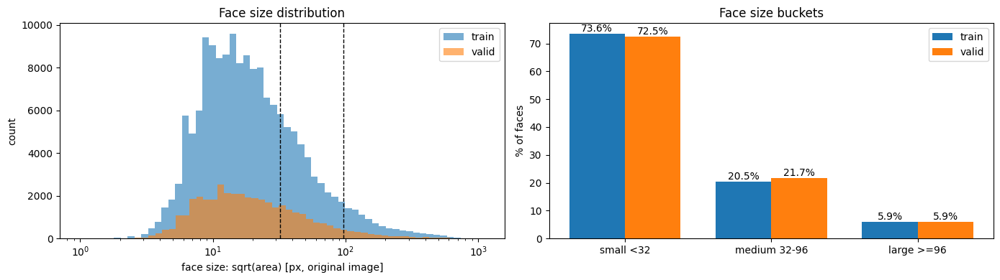

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for split, sides in SIDES.items():
    axes[0].hist(sides, bins=np.logspace(0, np.log10(max(sides.max(), 2)), 60), alpha=0.6, label=split)
for x in (SMALL_MAX, MEDIUM_MAX):
    axes[0].axvline(x, color="k", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_xlabel("face size: sqrt(area) [px, original image]")
axes[0].set_ylabel("count"); axes[0].set_title("Face size distribution"); axes[0].legend()

w = 0.38
for i, split in enumerate(SIDES):
    pct = [DATA_STATS[split]["size_pct"][b] for b in BUCKETS]
    bars = axes[1].bar(np.arange(3) + (i - 0.5) * w, pct, w, label=split)
    axes[1].bar_label(bars, fmt="%.1f%%")
axes[1].set_xticks(range(3), [f"small <{SMALL_MAX}", f"medium {SMALL_MAX}-{MEDIUM_MAX}", f"large >={MEDIUM_MAX}"])
axes[1].set_ylabel("% of faces"); axes[1].set_title("Face size buckets"); axes[1].legend()
plt.tight_layout(); plt.show()

### ภาพตัวอย่างพร้อม bounding box (6 ภาพ)
สีกล่อง: <span style="color:red">แดง = เล็ก</span>, <span style="color:orange">ส้ม = กลาง</span>, <span style="color:green">เขียว = ใหญ่</span>

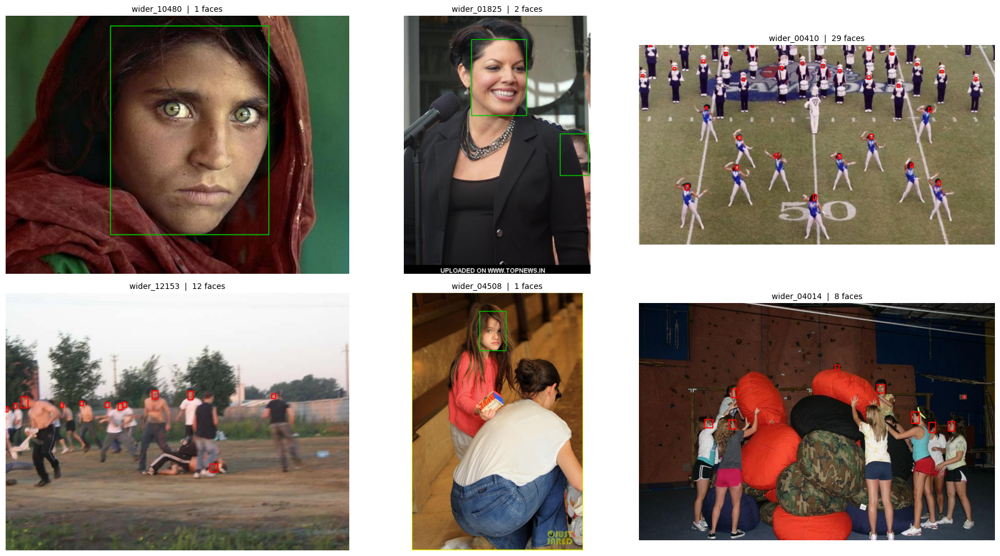

In [9]:
import cv2

BUCKET_COLORS = {"small": (255, 0, 0), "medium": (255, 165, 0), "large": (0, 200, 0)}  # RGB

def draw_gt(info):
    img = cv2.cvtColor(cv2.imread(info["path"]), cv2.COLOR_BGR2RGB)
    lw = max(1, round(max(img.shape[:2]) / 500))
    for x1, y1, x2, y2 in info["boxes"]:
        color = BUCKET_COLORS[size_bucket(np.sqrt((x2 - x1) * (y2 - y1)))]
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, lw)
    return img

rng = random.Random(SEED)
candidates = [k for k, v in SPLIT_INFO["train"].items() if v["boxes"]]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, key in zip(axes.ravel(), rng.sample(candidates, 6)):
    info = SPLIT_INFO["train"][key]
    ax.imshow(draw_gt(info)); ax.axis("off")
    ax.set_title(f"{Path(key).name[:40]}  |  {len(info['boxes'])} faces", fontsize=10)
plt.tight_layout(); plt.show()

## 5. สร้าง `data.yaml`
1 class = `face`

In [10]:
import yaml

DATA_YAML = DATASET_DIR / "data.yaml"
data_cfg = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": f"{VAL_SPLIT}/images",
    "nc": 1,
    "names": ["face"],
}
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False))
print(DATA_YAML.read_text())

path: /content/datasets/wider_face
train: train/images
val: valid/images
nc: 1
names:
- face



## 6. Train

- ผลทั้งหมดเขียนลง `DRIVE_OUTPUT_DIR/RUN_NAME` บน Google Drive (`last.pt` ทุก epoch, `best.pt`, `epochN.pt` ทุก `SAVE_PERIOD` epoch, `results.csv`, กราฟ)
- หลัง epoch แรกจะ print **เวลาต่อ epoch และเวลาที่คาดว่าจะใช้ทั้งหมด** (รวม validation แต่ละ epoch แล้ว) และเตือนถ้าน่าจะเกิน `SESSION_HOURS_LIMIT`
- เวลาของแต่ละ epoch ถูกบันทึกลง `epoch_times.json` ใน Drive เพื่อรวมเวลาได้ถูกต้องแม้ต้อง resume หลายรอบ

**สถานะของ run** ตรวจจาก `last.pt`: Ultralytics จะลบ optimizer state ออกจาก checkpoint และตั้ง `epoch = -1` เมื่อ train จบ (ครบหรือ early stop) → ถ้า `epoch >= 0` แปลว่ายังไม่จบ ต้อง resume

In [11]:
def checkpoint_status(path):
    # Returns "missing", "finished", "incomplete" or "corrupt"
    path = Path(path)
    if not path.exists():
        return "missing"
    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
    except Exception as e:
        print(f"Could not read {path}: {e}")
        return "corrupt"
    return "finished" if ckpt.get("epoch", -1) == -1 else "incomplete"

def attach_timing_callbacks(model):
    state = {"t0": None, "first": True, "session_start": time.time()}

    def on_train_epoch_start(trainer):
        state["t0"] = time.time()

    def on_fit_epoch_end(trainer):
        if state["t0"] is None:
            return
        dt = time.time() - state["t0"]   # train + val time of this epoch
        f = Path(trainer.save_dir) / "epoch_times.json"
        times = json.loads(f.read_text()) if f.exists() else {}
        times[str(trainer.epoch + 1)] = dt
        f.write_text(json.dumps(times, indent=1))

        done = trainer.epoch + 1
        remaining = trainer.epochs - done
        if state["first"] or done % 10 == 0:
            state["first"] = False
            eta_h = dt * remaining / 3600
            print("\n" + "=" * 80)
            print(f"[timing] epoch {done}/{trainer.epochs} took {dt / 60:.1f} min "
                  f"| elapsed (all sessions) {sum(times.values()) / 3600:.2f} h "
                  f"| est. remaining {eta_h:.2f} h for {remaining} epochs (early stopping may finish sooner)")
            session_h = (time.time() - state["session_start"]) / 3600 + eta_h
            if session_h > SESSION_HOURS_LIMIT:
                print(f"[timing] WARNING: this session would need ~{session_h:.1f} h total "
                      f"(> SESSION_HOURS_LIMIT={SESSION_HOURS_LIMIT} h). Checkpoints are on Drive -> if the "
                      f"session ends, reconnect and Run all to resume. To finish sooner: lower EPOCHS or IMGSZ.")
            print("=" * 80 + "\n")

    model.add_callback("on_train_epoch_start", on_train_epoch_start)
    model.add_callback("on_fit_epoch_end", on_fit_epoch_end)
    return model

print("Run status:", checkpoint_status(LAST_PT), "->", LAST_PT)

Run status: missing -> /content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/weights/last.pt


### 6.1 Train (เริ่มใหม่)
ถ้าใน Drive มี run นี้อยู่แล้ว (ยังไม่จบหรือจบแล้ว) cell นี้จะ **ข้าม** — ให้ cell 6.2 จัดการ resume แทน

In [12]:
status = checkpoint_status(LAST_PT)
if status == "missing":
    model = attach_timing_callbacks(YOLO(MODEL_NAME))
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=PATIENCE,
        save_period=SAVE_PERIOD,
        project=DRIVE_OUTPUT_DIR,
        name=RUN_NAME,
        exist_ok=True,       # keep a fixed run dir so resume/eval can find it
        seed=SEED,
        cache=False,         # RAM caching of 12.9k images would exceed free Colab RAM
        plots=True,
    )
else:
    print(f"Run already exists ({status}) at {RUN_DIR} -> skipping fresh training. See 6.2.")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/wider_face/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_widerface_960, nbs=64, nms=None, opset=None

### 6.3 สรุปการ train

In [13]:
import pandas as pd

assert BEST_PT.exists(), f"{BEST_PT} not found - training did not produce best.pt"
df = pd.read_csv(RUN_DIR / "results.csv")
df.columns = [c.strip() for c in df.columns]

times_file = RUN_DIR / "epoch_times.json"
if times_file.exists():
    train_seconds = sum(json.loads(times_file.read_text()).values())
elif "time" in df.columns:
    train_seconds = float(df["time"].iloc[-1])
else:
    train_seconds = float("nan")

best_row = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
TRAIN_INFO = {
    "model": MODEL_NAME,
    "requested_model": REQUESTED_MODEL,
    "ultralytics": ultralytics.__version__,
    "gpu": GPU_NAME,
    "epochs_planned": EPOCHS,
    "epochs_trained": int(len(df)),
    "early_stopped": bool(len(df) < EPOCHS),
    "best_epoch": int(best_row["epoch"]) + (0 if df["epoch"].min() >= 1 else 1),
    "train_time_h": round(train_seconds / 3600, 2),
    "min_per_epoch": round(train_seconds / 60 / max(len(df), 1), 1),
    "imgsz": IMGSZ, "batch": BATCH, "patience": PATIENCE,
}
(RUN_DIR / "train_info.json").write_text(json.dumps(TRAIN_INFO, indent=1))
for k, v in TRAIN_INFO.items():
    print(f"{k:16s}: {v}")

model           : yolo26s.pt
requested_model : yolo26s.pt
ultralytics     : 8.4.175
gpu             : NVIDIA L4
epochs_planned  : 40
epochs_trained  : 40
early_stopped   : False
best_epoch      : 38
train_time_h    : 3.88
min_per_epoch   : 5.8
imgsz           : 960
batch           : 16
patience        : 10


## 7. Evaluate บน validation set

### 7.1 Metrics มาตรฐานของ Ultralytics
`max_det=1000` เพราะบางภาพใน WIDER FACE มีหน้ามากกว่า 300 (ค่า default)

In [14]:
best_model = YOLO(str(BEST_PT))
val_metrics = best_model.val(
    data=str(DATA_YAML), split="val", imgsz=IMGSZ, batch=16, max_det=1000,
    plots=True, project=DRIVE_OUTPUT_DIR, name=f"{RUN_NAME}_val", exist_ok=True,
)
VAL_DIR = Path(val_metrics.save_dir)
OVERALL = {
    "precision": round(float(val_metrics.box.mp), 4),
    "recall": round(float(val_metrics.box.mr), 4),
    "mAP50": round(float(val_metrics.box.map50), 4),
    "mAP50-95": round(float(val_metrics.box.map), 4),
    "inference_ms_per_img": round(float(val_metrics.speed.get("inference", float("nan"))), 2),
}
print(json.dumps(OVERALL, indent=1))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3707.7±1165.1 MB/s, size: 233.3 KB)
val: Scanning /content/datasets/wider_face/valid/labels.cache... 3226 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3226/3226 966.5Mit/s 0.0s
val: /content/datasets/wider_face/valid/images/wider_01060.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 202/202 5.0it/s 40.2s
                   all       3226      39707      0.876      0.701      0.793       0.43
Speed: 1.0ms preprocess, 7.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960_val
{
 "precision": 0.8762,
 "recall": 0.701,
 "mAP50": 0.7934,
 "mAP50-95": 0.4295,
 "inference_ms_per_img": 7.53
}


### 7.2 แยกผลตามขนาดหน้า (เล็ก / กลาง / ใหญ่)
ระบบจริงมี 2 โหมด:
- **kiosk** — หน้าใหญ่ทีละคน → ดูผลกลุ่ม **large**
- **ถ่ายทั้งห้อง** — หน้าเล็กหลายคน → ดูกลุ่ม **small / medium**

วิธีประเมิน (Ultralytics ไม่มีแยกขนาดให้ จึงคำนวณเอง):
1. **AP แยกขนาด** — ใช้ `pycocotools` (COCOeval) ซึ่งมีการแบ่ง small/medium/large มาตรฐาน (32² / 96² px²): ตอนคิด AP ของกลุ่มหนึ่ง GT กลุ่มอื่นจะถูก ignore ไม่ถูกนับเป็น FN และ detection ที่จับคู่กับ GT กลุ่มอื่นก็ไม่นับเป็น FP
2. **Operating point** (`conf ≥ CONF_OPERATING`, IoU ≥ 0.5) — recall = สัดส่วนหน้าในกลุ่มนั้นที่ถูกตรวจเจอจริงตอนใช้งาน, precision = สัดส่วน detection ขนาดนั้นที่เป็นหน้าจริง

ประเมินที่ inference size = `IMGSZ` และ `EXTRA_EVAL_IMGSZ` (ใช้ predictions ชุดเดียวกันทั้งสองวิธี) — ใช้เวลาราว 2–5 นาทีต่อขนาด

In [16]:
import contextlib, io
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

val_items = sorted(SPLIT_INFO[VAL_SPLIT].items())   # [(key, info)], image_id = index + 1

def build_coco_gt():
    images, anns = [], []
    for img_id, (key, info) in enumerate(val_items, start=1):
        images.append({"id": img_id, "file_name": key, "width": info["W"], "height": info["H"]})
        for x1, y1, x2, y2 in info["boxes"]:
            w, h = x2 - x1, y2 - y1
            anns.append({"id": len(anns) + 1, "image_id": img_id, "category_id": 1,
                         "bbox": [x1, y1, w, h], "area": w * h, "iscrowd": 0})
    gt = COCO()
    gt.dataset = {"info": {}, "licenses": [], "images": images, "annotations": anns,
                  "categories": [{"id": 1, "name": "face"}]}
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
    return gt

def run_predictions(model, imgsz, conf=0.001, max_det=1000, chunk=32):
    preds = {}
    paths = [info["path"] for _, info in val_items]
    for start in tqdm(range(0, len(paths), chunk), desc=f"predict @{imgsz}"):
        results = model.predict(paths[start:start + chunk], imgsz=imgsz, conf=conf, max_det=max_det,
                                batch=16, verbose=False)
        for i, r in enumerate(results, start=start + 1):
            preds[i] = (r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())
    return preds

def coco_size_eval(coco_gt, preds):
    dets = [{"image_id": img_id, "category_id": 1,
             "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])], "score": float(s)}
            for img_id, (boxes, scores) in preds.items() for b, s in zip(boxes, scores)]
    if not dets:
        return {}
    with contextlib.redirect_stdout(io.StringIO()):
        coco_dt = coco_gt.loadRes(dets)
        E = COCOeval(coco_gt, coco_dt, "bbox")
        E.params.maxDets = [10, 100, 1000]
        E.evaluate(); E.accumulate(); E.summarize()
    prec, rec = E.eval["precision"], E.eval["recall"]   # [T,R,K,A,M], [T,K,A,M]

    def mean_valid(x):
        x = x[x > -1]
        return round(float(x.mean()), 4) if x.size else float("nan")

    out = {}
    for a_idx, name in enumerate(["all", "small", "medium", "large"]):   # COCO areaRng order
        out[name] = {
            "AP50": mean_valid(prec[0, :, 0, a_idx, -1]),
            "AP50-95": mean_valid(prec[:, :, 0, a_idx, -1]),
            "max_recall50": mean_valid(rec[0, 0, a_idx, -1]),
        }
    return out

def box_iou(a, b):
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def side_of(boxes):
    return np.sqrt(np.clip((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), 0, None))

def operating_point(preds, conf_thr, iou_thr=0.5):
    st = {b: {"gt": 0, "found": 0, "tp": 0, "fp": 0} for b in BUCKETS}
    for img_id, (key, info) in enumerate(val_items, start=1):
        gt = np.array(info["boxes"], dtype=np.float32).reshape(-1, 4)
        gt_b = [size_bucket(s) for s in side_of(gt)]
        for b in gt_b:
            st[b]["gt"] += 1
        boxes, scores = preds[img_id]
        keep = scores >= conf_thr
        boxes = boxes[keep][np.argsort(-scores[keep])]
        if len(boxes) == 0:
            continue
        det_b = [size_bucket(s) for s in side_of(boxes)]
        if len(gt) == 0:
            for b in det_b:
                st[b]["fp"] += 1
            continue
        ious = box_iou(boxes, gt)
        matched = np.zeros(len(gt), bool)
        for d in range(len(boxes)):   # greedy matching by descending confidence
            row = np.where(matched, -1.0, ious[d])
            g = int(row.argmax())
            if row[g] >= iou_thr:
                matched[g] = True
                st[gt_b[g]]["found"] += 1
                st[gt_b[g]]["tp"] += 1
            else:
                st[det_b[d]]["fp"] += 1
    st["all"] = {k: sum(st[b][k] for b in BUCKETS) for k in ["gt", "found", "tp", "fp"]}
    out = {}
    for b, s in st.items():
        out[b] = {"n_gt": s["gt"],
                  "recall": round(s["found"] / s["gt"], 4) if s["gt"] else float("nan"),
                  "precision": round(s["tp"] / (s["tp"] + s["fp"]), 4) if (s["tp"] + s["fp"]) else float("nan")}
    return out

coco_gt = build_coco_gt()
eval_sizes = [IMGSZ] + ([EXTRA_EVAL_IMGSZ] if EXTRA_EVAL_IMGSZ and EXTRA_EVAL_IMGSZ != IMGSZ else [])
PER_SIZE = {}
for sz in eval_sizes:
    preds = run_predictions(best_model, sz)
    n_dets = sum(len(s) for _, s in preds.values())
    print(f"[{sz}] {n_dets:,} detections -> running COCOeval (silent, can take several minutes)...")
    t0 = time.time()
    coco_res = coco_size_eval(coco_gt, preds)
    print(f"[{sz}] COCOeval done in {time.time() - t0:.0f}s -> operating point...")
    PER_SIZE[sz] = {"coco": coco_res, "operating": operating_point(preds, CONF_OPERATING)}
    print(f"[{sz}] done")
    del preds

rows = []
for sz, res in PER_SIZE.items():
    for b in ["all"] + BUCKETS:
        rows.append({"infer_imgsz": sz, "faces": b, "n_gt": res["operating"][b]["n_gt"],
                     "AP50": res["coco"][b]["AP50"], "AP50-95": res["coco"][b]["AP50-95"],
                     "max_recall50": res["coco"][b]["max_recall50"],
                     f"P@{CONF_OPERATING}": res["operating"][b]["precision"],
                     f"R@{CONF_OPERATING}": res["operating"][b]["recall"]})
PER_SIZE_DF = pd.DataFrame(rows)
display(PER_SIZE_DF)

EVAL_RESULTS = {"overall_ultralytics": OVERALL, "conf_operating": CONF_OPERATING,
                "per_size": {str(k): v for k, v in PER_SIZE.items()}}
(RUN_DIR / "eval_results.json").write_text(json.dumps(EVAL_RESULTS, indent=1))
print("Saved", RUN_DIR / "eval_results.json")

predict @960:   0%|          | 0/101 [00:00<?, ?it/s]

[960] 344,231 detections -> running COCOeval (silent, can take several minutes)...
[960] COCOeval done in 308s -> operating point...
[960] done


predict @640:   0%|          | 0/101 [00:00<?, ?it/s]

[640] 337,528 detections -> running COCOeval (silent, can take several minutes)...
[640] COCOeval done in 303s -> operating point...
[640] done


,infer_imgsz,faces,n_gt,AP50,AP50-95,max_recall50,P@0.25,R@0.25
0,960,all,39697,0.7908,0.4298,0.8802,0.8297,0.7257
1,960,small,28764,0.7086,0.3264,0.8389,0.7753,0.6427
2,960,medium,8606,0.9643,0.6454,0.9884,0.9423,0.9363
3,960,large,2327,0.9836,0.7208,0.9910,0.9729,0.9716
4,640,all,39697,0.7102,0.3807,0.8130,0.7862,0.6498
5,640,small,28764,0.5953,0.2624,0.7472,0.7078,0.5414
6,640,medium,8606,0.9584,0.6287,0.9854,0.9388,0.9249
7,640,large,2327,0.9778,0.7202,0.9897,0.9725,0.9721


Saved /content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/eval_results.json


**อ่านผลยังไง**
- `AP50` / `AP50-95` ของกลุ่ม **large** สำคัญที่สุดสำหรับโหมด kiosk; กลุ่ม **small** สำหรับโหมดถ่ายทั้งห้อง
- `max_recall50` = recall สูงสุดที่ทำได้ถ้าตั้ง conf ต่ำมาก; `R@conf` = recall ตอนใช้งานจริงที่ threshold นั้น
- เทียบ `IMGSZ` (960) กับ `EXTRA_EVAL_IMGSZ` (640): ถ้ากลุ่ม large ที่ 640 แทบไม่ต่างจาก 960 → โหมด kiosk ใช้ ONNX 640 (เร็วกว่า ~2 เท่า) ได้เลย ส่วนโหมดถ่ายทั้งห้องใช้ 960
- ค่า AP จาก COCOeval อาจต่างจาก Ultralytics เล็กน้อย (วิธี interpolate ต่างกัน) — ใช้เทียบระหว่างกลุ่ม/ขนาดภาพเป็นหลัก

## 8. กราฟจาก Ultralytics
training curves, confusion matrix, PR curve (และ F1 curve ไว้ช่วยเลือก confidence threshold)

/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/results.png


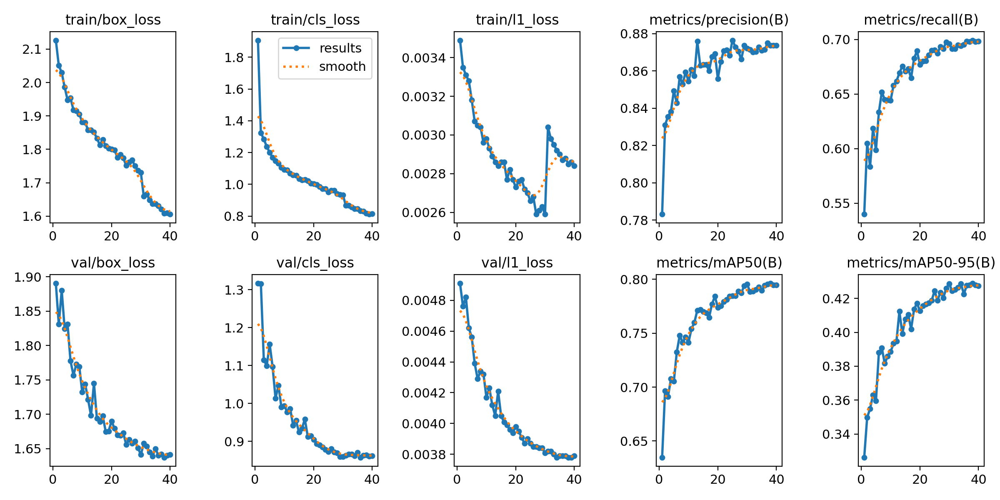

/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960_val/confusion_matrix.png


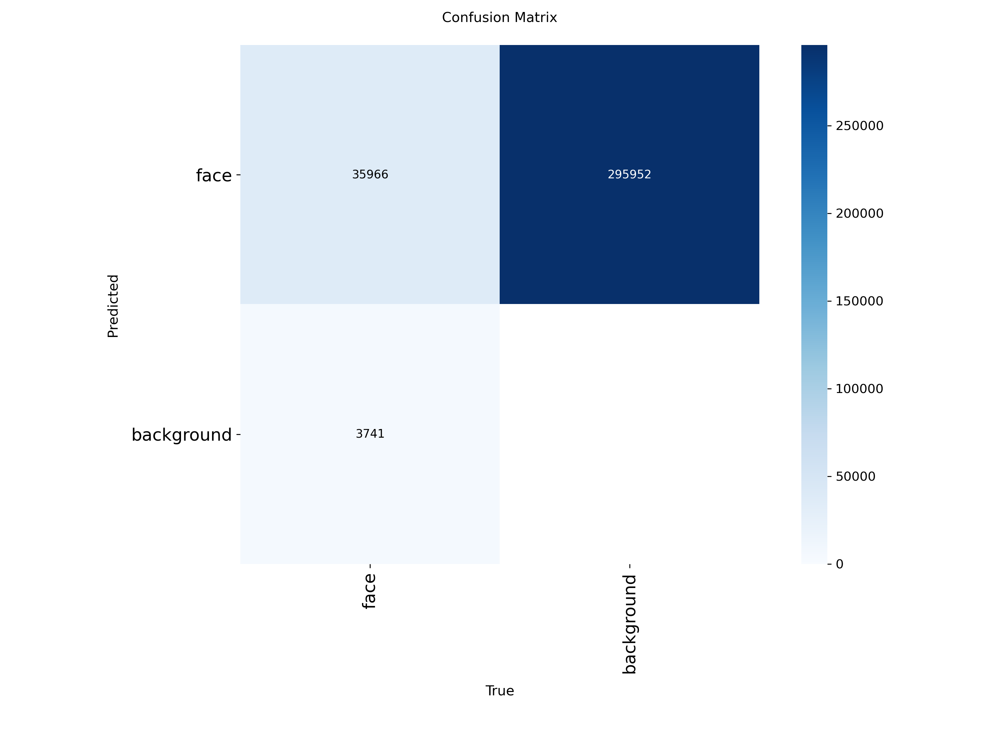

/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960_val/BoxPR_curve.png


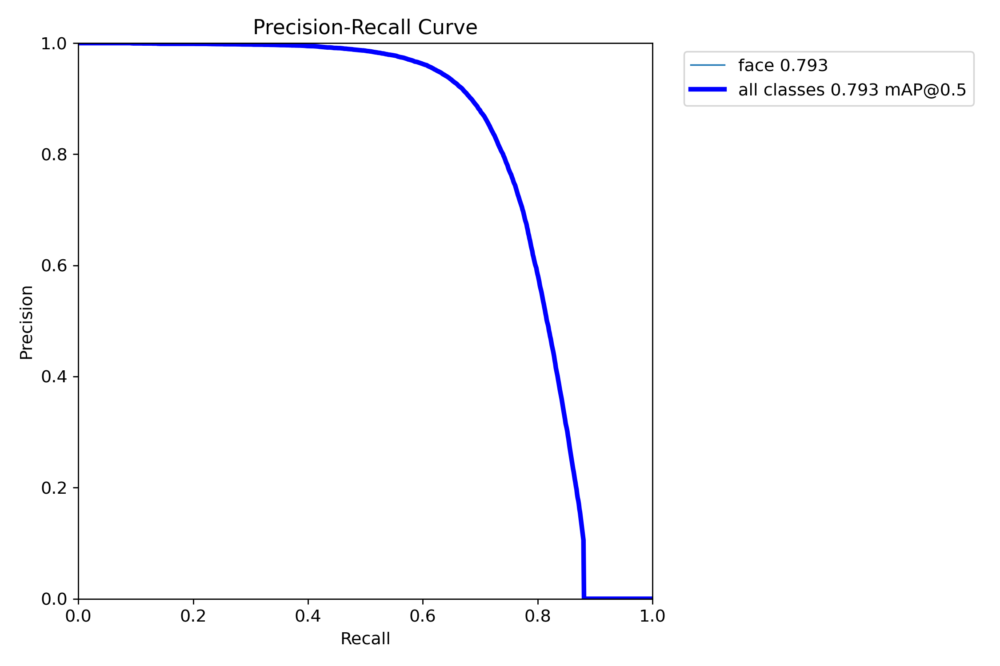

/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960_val/BoxF1_curve.png


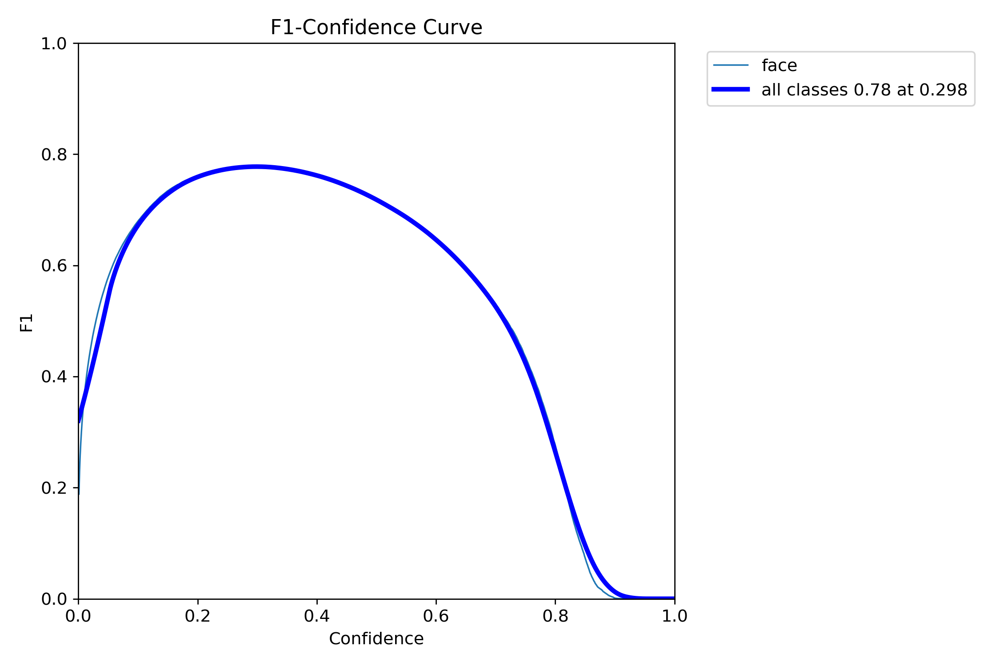

In [17]:
from IPython.display import Image as IPyImage, display

def show_first(*candidates, width=900):
    for p in candidates:
        if Path(p).exists():
            print(p)
            display(IPyImage(filename=str(p), width=width))
            return
    print("not found:", [Path(c).name for c in candidates])

show_first(RUN_DIR / "results.png", width=1200)
show_first(VAL_DIR / "confusion_matrix.png", RUN_DIR / "confusion_matrix.png", width=600)
show_first(VAL_DIR / "BoxPR_curve.png", VAL_DIR / "PR_curve.png", RUN_DIR / "BoxPR_curve.png", RUN_DIR / "PR_curve.png")
show_first(VAL_DIR / "BoxF1_curve.png", VAL_DIR / "F1_curve.png", RUN_DIR / "BoxF1_curve.png", RUN_DIR / "F1_curve.png")

## 9. Inference demo
- ภาพหลายหน้า (จำลองโหมดถ่ายทั้งห้อง) — รันทั้งที่ `IMGSZ` และ `EXTRA_EVAL_IMGSZ` เพื่อเทียบ
- ภาพหน้าเดียวใหญ่ๆ (จำลองโหมด kiosk)

ตัวเลขบนกล่อง = confidence

[many faces @ 960] wider_02824: GT=25, detected=24, top conf=[0.8399999737739563, 0.8399999737739563, 0.8100000023841858, 0.8100000023841858, 0.8100000023841858, 0.8100000023841858, 0.800000011920929, 0.800000011920929, 0.800000011920929, 0.7400000095367432]
[many faces @ 640] wider_02824: GT=25, detected=24, top conf=[0.8399999737739563, 0.8299999833106995, 0.8199999928474426, 0.800000011920929, 0.7900000214576721, 0.7799999713897705, 0.7799999713897705, 0.7699999809265137, 0.7599999904632568, 0.6899999976158142]
[many faces @ 960] wider_00539: GT=19, detected=10, top conf=[0.8100000023841858, 0.800000011920929, 0.7699999809265137, 0.5699999928474426, 0.5299999713897705, 0.4399999976158142, 0.4399999976158142, 0.30000001192092896, 0.30000001192092896, 0.28999999165534973]
[many faces @ 640] wider_00539: GT=19, detected=5, top conf=[0.8199999928474426, 0.75, 0.699999988079071, 0.4000000059604645, 0.3499999940395355]
[single large face @ 960] wider_02402: GT=1, detected=1, top conf=[0.7

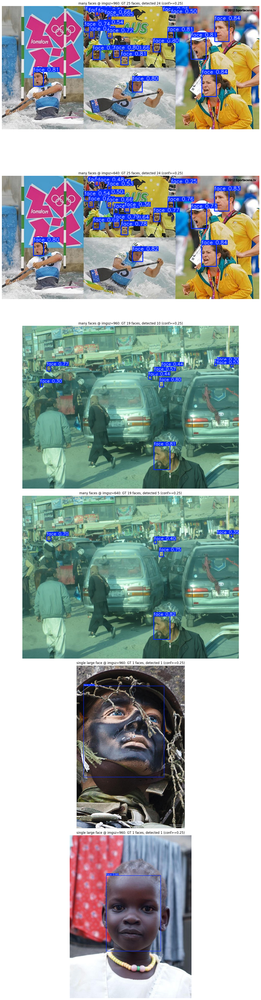

In [20]:
# ---- Demo settings ----
DEMO_SEED = None          # None = new random images every run; set an int (e.g. 42) to get the same images again
MULTI_RANGE = (15, 40)    # number of faces for the "classroom" image
N_MULTI = 2               # how many multi-face images to show
N_SINGLE = 2              # how many single-face images to show
SINGLE_TOP_K = 50         # pick single-face images randomly among the K largest faces

rng = random.Random(DEMO_SEED)
counts = {k: len(v["boxes"]) for k, v in val_items}

multi_pool = [k for k, c in counts.items() if MULTI_RANGE[0] <= c <= MULTI_RANGE[1]] or [max(counts, key=counts.get)]
multi_keys = rng.sample(multi_pool, min(N_MULTI, len(multi_pool)))

single_pool = sorted([k for k, c in counts.items() if c == 1],
                     key=lambda k: side_of(np.array(SPLIT_INFO[VAL_SPLIT][k]["boxes"]))[0], reverse=True)
single_keys = rng.sample(single_pool[:SINGLE_TOP_K], min(N_SINGLE, len(single_pool[:SINGLE_TOP_K])))

demo_runs = []
for k in multi_keys:
    demo_runs.append((k, IMGSZ, "many faces"))
    if EXTRA_EVAL_IMGSZ and EXTRA_EVAL_IMGSZ != IMGSZ:
        demo_runs.append((k, EXTRA_EVAL_IMGSZ, "many faces"))
for k in single_keys:
    demo_runs.append((k, IMGSZ, "single large face"))

fig, axes = plt.subplots(len(demo_runs), 1, figsize=(14, 9 * len(demo_runs)))
for ax, (key, sz, title) in zip(np.atleast_1d(axes), demo_runs):
    info = SPLIT_INFO[VAL_SPLIT][key]
    r = best_model.predict(info["path"], imgsz=sz, conf=CONF_OPERATING, max_det=1000, verbose=False)[0]
    confs = sorted(r.boxes.conf.cpu().numpy().round(2).tolist(), reverse=True)
    ax.imshow(r.plot(line_width=2, font_size=10)[:, :, ::-1]); ax.axis("off")
    ax.set_title(f"{title} @ imgsz={sz}: GT {len(info['boxes'])} faces, detected {len(confs)} (conf>={CONF_OPERATING})")
    print(f"[{title} @ {sz}] {Path(key).name}: GT={len(info['boxes'])}, detected={len(confs)}, "
          f"top conf={confs[:10]}")
plt.tight_layout(); plt.show()

# keep variables used by later cells (ONNX test uses multi_key)
multi_key, single_key = multi_keys[0], single_keys[0]

## 10. Export (`best.pt` + ONNX) ลง Drive
- ONNX ไว้ใช้ใน web app ภายหลัง (onnxruntime / onnxruntime-web) — input เป็นขนาด fix จึง export 2 ไฟล์: `IMGSZ` (ถ่ายทั้งห้อง) และ `EXTRA_EVAL_IMGSZ` (kiosk, เร็วกว่า) จาก weights ชุดเดียวกัน
- YOLO26 เป็นแบบ end-to-end (NMS-free) → output ปกติเป็น `(1, 300, 6)` = `[x1, y1, x2, y2, conf, class]` ไม่ต้องทำ NMS เอง
  ถ้า fallback เป็น YOLO11 output จะเป็น `(1, 5, 8400)` และต้องทำ NMS เอง — cell ทดสอบด้านล่างรองรับทั้งสองแบบ

In [21]:
EXPORT_DIR = RUN_DIR / "export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

EXPORT_PT = EXPORT_DIR / f"{RUN_NAME}_best.pt"
shutil.copy2(BEST_PT, EXPORT_PT)

# Each export overwrites best.onnx next to best.pt -> copy right away under a size-specific name
EXPORT_ONNX_FILES = {}
for sz in eval_sizes:
    onnx_src = YOLO(str(BEST_PT)).export(format="onnx", imgsz=sz, simplify=True, dynamic=False)
    EXPORT_ONNX_FILES[sz] = EXPORT_DIR / f"{RUN_NAME}_best_{sz}.onnx"
    shutil.copy2(onnx_src, EXPORT_ONNX_FILES[sz])
EXPORT_ONNX = EXPORT_ONNX_FILES[IMGSZ]

for p in [EXPORT_PT, *EXPORT_ONNX_FILES.values()]:
    print(f"{p}  ({p.stat().st_size / 1e6:.1f} MB)")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 47.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 5, 18900) (19.4 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.2s, saved as '/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/weights/best.onnx' (36.6 MB)

Export complete (2.7s)
Results saved to /content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/weights/best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/roll_call/yolo_face/yolo26s_widerface_960/weights/best.onnx imgsz=960 
Validate

### 10.1 ทดสอบโหลด ONNX แล้ว inference 1 ภาพ
ใช้ `onnxruntime` + preprocessing เขียนเอง (letterbox → RGB → /255 → NCHW) แบบเดียวกับที่ web app จะต้องทำ แล้วเทียบจำนวนหน้ากับผลจาก PyTorch

ONNX input : images [1, 3, 960, 960]
ONNX output: output0 [1, 5, 18900]
{
 "output_shape": [
  1,
  5,
  18900
 ],
 "faces_onnx": 21,
 "faces_pytorch": 24,
 "gt_faces": 25,
 "cpu_ms_incl_preprocess": 141.9,
 "ok": false
}


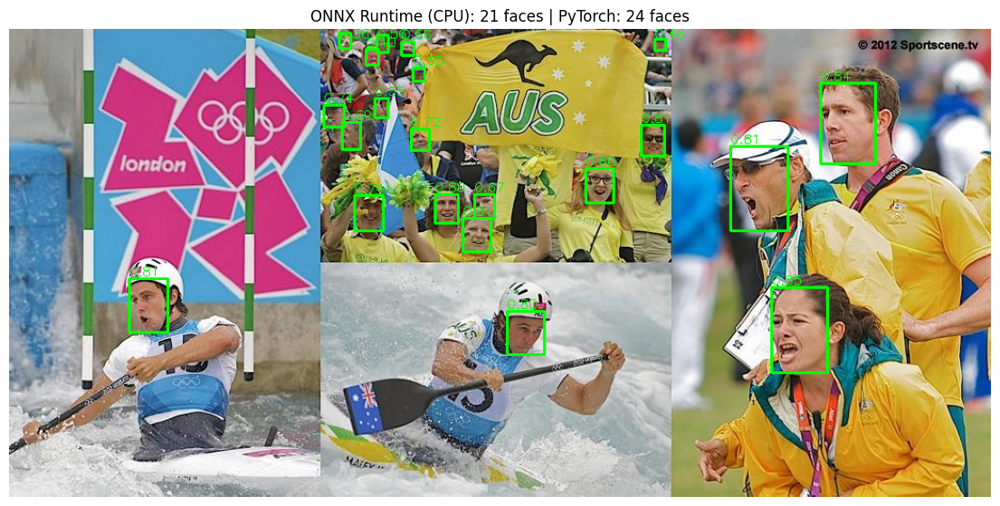

In [23]:
import onnxruntime as ort

def letterbox(img, size, color=(114, 114, 114)):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    dw, dh = (size - nw) / 2, (size - nh) / 2
    img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, bottom = round(dh - 0.1), round(dh + 0.1)
    left, right = round(dw - 0.1), round(dw + 0.1)
    return cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=color), r, (left, top)

def onnx_detect(session, img_bgr, size, conf_thr=0.25, iou_thr=0.7):   # iou 0.7 = Ultralytics default NMS
    inp, r, (padx, pady) = letterbox(img_bgr, size)
    blob = inp[:, :, ::-1].transpose(2, 0, 1)[None].astype(np.float32) / 255.0
    out = session.run(None, {session.get_inputs()[0].name: np.ascontiguousarray(blob)})[0]
    if out.ndim == 3 and out.shape[2] == 6:            # end-to-end: [x1,y1,x2,y2,conf,cls]
        det = out[0]
        boxes, scores = det[:, :4], det[:, 4]
        keep = scores >= conf_thr
        boxes, scores = boxes[keep], scores[keep]
    else:                                               # raw head: (1, 4+nc, N) -> needs NMS
        pred = out[0].T
        xywh, scores = pred[:, :4], pred[:, 4:].max(1)
        keep = scores >= conf_thr
        xywh, scores = xywh[keep], scores[keep]
        boxes = np.concatenate([xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2], 1)
        tlwh = np.concatenate([boxes[:, :2], boxes[:, 2:] - boxes[:, :2]], 1)   # NMSBoxes expects [x, y, w, h]
        idx = cv2.dnn.NMSBoxes(tlwh.tolist(), scores.tolist(), conf_thr, iou_thr)
        idx = np.array(idx).reshape(-1)
        boxes, scores = boxes[idx], scores[idx]
    boxes = (boxes - [padx, pady, padx, pady]) / r      # undo letterbox
    return boxes, scores, out.shape

sess = ort.InferenceSession(str(EXPORT_ONNX), providers=["CPUExecutionProvider"])
print("ONNX input :", sess.get_inputs()[0].name, sess.get_inputs()[0].shape)
print("ONNX output:", sess.get_outputs()[0].name, sess.get_outputs()[0].shape)

test_info = SPLIT_INFO[VAL_SPLIT][multi_key]
img = cv2.imread(test_info["path"])
t0 = time.time()
onnx_boxes, onnx_scores, ONNX_OUT_SHAPE = onnx_detect(sess, img, IMGSZ, CONF_OPERATING)
onnx_ms = (time.time() - t0) * 1000
pt_count = len(best_model.predict(test_info["path"], imgsz=IMGSZ, conf=CONF_OPERATING, verbose=False)[0].boxes)

ONNX_CHECK = {"output_shape": list(ONNX_OUT_SHAPE), "faces_onnx": int(len(onnx_boxes)),
              "faces_pytorch": int(pt_count), "gt_faces": len(test_info["boxes"]),
              "cpu_ms_incl_preprocess": round(onnx_ms, 1)}
ONNX_CHECK["ok"] = bool(len(onnx_boxes) > 0 and abs(len(onnx_boxes) - pt_count) <= max(2, 0.1 * pt_count))
print(json.dumps(ONNX_CHECK, indent=1))

vis = img.copy()
for (x1, y1, x2, y2), s in zip(onnx_boxes.astype(int), onnx_scores):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(vis, f"{s:.2f}", (x1, max(y1 - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)
plt.figure(figsize=(14, 9)); plt.imshow(vis[:, :, ::-1]); plt.axis("off")
plt.title(f"ONNX Runtime (CPU): {len(onnx_boxes)} faces | PyTorch: {pt_count} faces"); plt.show()

## 11. สรุปผล (copy ข้อความทั้งหมดด้านล่างกลับไปให้ดู)

In [24]:
def fmt(x):
    return f"{x:.4f}" if isinstance(x, float) else str(x)

lines = []
lines.append("===== NOTEBOOK 1 SUMMARY: YOLO face detector on WIDER FACE =====")
lines.append(f"Model           : {TRAIN_INFO['model']} (requested {TRAIN_INFO['requested_model']}) | "
             f"ultralytics {TRAIN_INFO['ultralytics']} | GPU {TRAIN_INFO['gpu']}")
lines.append(f"Train config    : imgsz={IMGSZ}, batch={BATCH}, epochs={EPOCHS}, patience={PATIENCE}, seed={SEED}")
lines.append(f"Epochs trained  : {TRAIN_INFO['epochs_trained']}/{EPOCHS} "
             f"(early stopped: {TRAIN_INFO['early_stopped']}), best epoch {TRAIN_INFO['best_epoch']}")
lines.append(f"Train time      : {TRAIN_INFO['train_time_h']} h (~{TRAIN_INFO['min_per_epoch']} min/epoch incl. val)")
for split in ["train", VAL_SPLIT]:
    s = DATA_STATS[split]
    lines.append(f"Data [{split:5s}]    : {s['images']} imgs, {s['labels']} labels, {s['faces']} faces, "
                 f"empty={s['empty_labels']}, no-label={s['images_without_label']}, "
                 f"orphan-label={s['labels_without_image']}, bad-cls={s['non_zero_class_ids']}, "
                 f"size% S/M/L={s['size_pct']['small']}/{s['size_pct']['medium']}/{s['size_pct']['large']}")
lines.append(f"Val (Ultralytics, imgsz={IMGSZ}, max_det=1000): " + ", ".join(f"{k}={fmt(v)}" for k, v in OVERALL.items()))
lines.append(f"Per face size (S<{SMALL_MAX}px, M {SMALL_MAX}-{MEDIUM_MAX}px, L>={MEDIUM_MAX}px; "
             f"P/R at conf>={CONF_OPERATING}, IoU>=0.5):")
for sz, res in PER_SIZE.items():
    for b in ["all"] + BUCKETS:
        c, o = res["coco"][b], res["operating"][b]
        lines.append(f"  @{sz:<5d} {b:7s} n={o['n_gt']:6d}  AP50={fmt(c['AP50'])}  AP50-95={fmt(c['AP50-95'])}  "
                     f"maxR50={fmt(c['max_recall50'])}  P={fmt(o['precision'])}  R={fmt(o['recall'])}")
lines.append(f"ONNX check      : {ONNX_CHECK}")
lines.append(f"Drive run dir   : {RUN_DIR}")
lines.append(f"best.pt         : {EXPORT_PT}")
for sz, p in EXPORT_ONNX_FILES.items():
    lines.append(f"ONNX @{sz:<5d}     : {p}")
lines.append(f"data.yaml (local, recreate in notebook 2): {DATA_YAML}")
lines.append("================================================================")

SUMMARY_TEXT = "\n".join(lines)
(RUN_DIR / "summary.txt").write_text(SUMMARY_TEXT)
print(SUMMARY_TEXT)

===== NOTEBOOK 1 SUMMARY: YOLO face detector on WIDER FACE =====
Model           : yolo26s.pt (requested yolo26s.pt) | ultralytics 8.4.175 | GPU NVIDIA L4
Train config    : imgsz=960, batch=16, epochs=40, patience=10, seed=42
Epochs trained  : 40/40 (early stopped: False), best epoch 38
Train time      : 3.88 h (~5.8 min/epoch incl. val)
Data [train]    : 12880 imgs, 12880 labels, 159393 faces, empty=4, no-label=0, orphan-label=0, bad-cls={}, size% S/M/L=73.6/20.5/5.9
Data [valid]    : 3226 imgs, 3226 labels, 39697 faces, empty=0, no-label=0, orphan-label=0, bad-cls={}, size% S/M/L=72.5/21.7/5.9
Val (Ultralytics, imgsz=960, max_det=1000): precision=0.8762, recall=0.7010, mAP50=0.7934, mAP50-95=0.4295, inference_ms_per_img=7.5300
Per face size (S<32px, M 32-96px, L>=96px; P/R at conf>=0.25, IoU>=0.5):
  @960   all     n= 39697  AP50=0.7908  AP50-95=0.4298  maxR50=0.8802  P=0.8297  R=0.7257
  @960   small   n= 28764  AP50=0.7086  AP50-95=0.3264  maxR50=0.8389  P=0.7753  R=0.6427
  @960  